# 02 - Analisis del equipo

Diagnostico del RCD Mallorca en LaLiga 2025/26 a partir de los ficheros de `data/`.
Responde a la primera pregunta del trabajo: si el descenso respondio al rendimiento del
equipo o fue un accidente de calendario.

Parte de los ficheros generados en el notebook 01. Se ejecuta de arriba abajo desde cero.

**Ficheros que genera**

| Fichero | Contenido |
|---|---|
| `clasificacion_xpts_laliga_2526.csv` | Puntos reales y esperados de los 20 equipos |
| `acciones_def_mallorca.csv` | Acciones defensivas del Mallorca con sus coordenadas |
| `altura_defensiva_laliga_2526.csv` | Altura defensiva media de cada equipo |
| `estilo_equipos_laliga_2526.csv` | Pases, acierto, juego largo y altura por equipo |
| `pases_clave_laliga_2526.csv` | Pases clave con origen, destino y si fueron centro |

## 1. Carga de datos

In [1]:
# Subimos a la carpeta raiz del proyecto para que las rutas relativas funcionen
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Importamos pandas para manejar los datos
import pandas as pd
# Importamos numpy para calculos numericos
import numpy as np
# Importamos matplotlib para construir las figuras
import matplotlib.pyplot as plt
# Importamos las herramientas de dibujo de campos de futbol
from mplsoccer import VerticalPitch
# Importamos unidecode para normalizar nombres
from unidecode import unidecode

# Definimos la funcion que normaliza un nombre para cruzar entre fuentes
def normalizar(nombre):
    # Quitamos acentos, pasamos a minusculas y limpiamos separadores
    n = unidecode(str(nombre)).lower().replace(".", "").replace("-", " ")
    # Eliminamos espacios sobrantes
    return " ".join(n.split())

# Cargamos la tabla de equipos en formato largo
largo = pd.read_csv("data/equipos_largo_laliga_2526.csv")

# Cargamos los disparos ya limpios
disparos = pd.read_csv("data/disparos_laliga_2526_limpio.csv")

# Filtramos los partidos del Mallorca
mallorca = largo[largo["equipo"] == "Mallorca"]

# Comprobamos que la carga es correcta
print("Equipos por partido:", largo.shape)
print("Disparos:", disparos.shape)
print("Partidos del Mallorca:", len(mallorca))

Equipos por partido: (760, 18)
Disparos: (9523, 21)
Partidos del Mallorca: 38


## 2. Balance de la temporada

Validamos primero que los datos cuadran con el resultado real.

In [2]:
# Calculamos los totales de la temporada del Mallorca
resumen = mallorca[["points", "goals", "goles_encajados", "xg", "xga"]].sum()

# Mostramos los totales
print("PUNTOS:", round(resumen["points"]))
print("GOLES A FAVOR:", round(resumen["goals"]))
print("GOLES EN CONTRA:", round(resumen["goles_encajados"]))
print("xG A FAVOR:", round(resumen["xg"], 2))
print("xG EN CONTRA:", round(resumen["xga"], 2))

# Comparamos el rendimiento real con el esperado en ataque
print("DIFERENCIA ATAQUE (goles - xG):", round(resumen["goals"] - resumen["xg"], 2))

# Comparamos el rendimiento real con el esperado en defensa
print("DIFERENCIA DEFENSA (encajados - xGA):", round(resumen["goles_encajados"] - resumen["xga"], 2))

PUNTOS: 42
GOLES A FAVOR: 47
GOLES EN CONTRA: 57
xG A FAVOR: 47.51
xG EN CONTRA: 65.85
DIFERENCIA ATAQUE (goles - xG): -0.51
DIFERENCIA DEFENSA (encajados - xGA): -8.85


El Mallorca marco 47 goles con 47,51 de xG: convirtio exactamente lo que merecian
sus ocasiones. En defensa encajo 57 goles con 65,85 de xGA, es decir, **recibio casi
9 goles menos de los que sus concesiones merecian**. Ese desfase se analiza en el
apartado 8.

## 3. Posicion en la liga

Usamos la **mediana** como referencia, no la media: Barcelona (99,67 de xG) y Real Madrid
(81,49) son valores atipicos que distorsionan la media al alza.

In [3]:
# Agrupamos los totales de toda la temporada por equipo
tabla = largo.groupby("equipo")[["points", "goals", "goles_encajados", "xg", "xga"]].sum()

# Ordenamos de menor a mayor xGA (los mejores defensivamente primero)
tabla = tabla.sort_values("xga")

# Anadimos la posicion en el ranking defensivo
tabla["rank_xga"] = range(1, len(tabla) + 1)

# Anadimos la posicion en el ranking ofensivo
tabla["rank_xg"] = tabla["xg"].rank(ascending=False).astype(int)

# Mostramos la tabla completa redondeada
print(tabla.round(2))

# Calculamos las medianas de la liga como referencia
print("\nMEDIANA xG:", round(tabla["xg"].median(), 2))
print("MEDIANA xGA:", round(tabla["xga"].median(), 2))

                 points  goals  goles_encajados     xg    xga  rank_xga  \
equipo                                                                    
Real Madrid          86     77               35  81.49  44.99         1   
Athletic Club        45     43               58  55.65  47.12         2   
Getafe               51     32               38  33.96  48.31         3   
Real Betis           60     59               48  61.30  50.32         4   
Barcelona            94     95               36  99.67  50.71         5   
Osasuna              42     44               50  51.46  51.64         6   
Alaves               43     44               56  53.58  52.97         7   
Atletico Madrid      69     62               44  68.11  53.14         8   
Villarreal           72     72               46  68.84  53.67         9   
Valencia             49     46               55  53.95  55.53        10   
Rayo Vallecano       50     41               44  59.98  56.34        11   
Celta Vigo           54  

El Mallorca quedo **17o de 20 tanto en xG como en xGA**. No era un equipo con buen
ataque y mala defensa: estaba entre los cuatro peores por ambos lados. El deficit
defensivo (+9,92 sobre la mediana) es aproximadamente 1,6 veces el ofensivo (-6,26).

## 4. Puntos esperados

In [4]:
# Agrupamos los puntos esperados de toda la temporada por equipo
xpts = largo.groupby("equipo")[["points", "expected_points"]].sum()

# Calculamos la diferencia entre puntos reales y esperados
xpts["diferencia"] = xpts["points"] - xpts["expected_points"]

# Ordenamos por puntos esperados de mayor a menor
xpts = xpts.sort_values("expected_points", ascending=False)

# Mostramos la tabla redondeada
print(xpts.round(2))

                 points  expected_points  diferencia
equipo                                              
Barcelona            94            79.06       14.94
Real Madrid          86            75.93       10.07
Villarreal           72            63.28        8.72
Atletico Madrid      69            61.83        7.17
Real Betis           60            59.96        0.04
Athletic Club        45            56.90      -11.90
Rayo Vallecano       50            55.90       -5.90
Real Sociedad        46            54.61       -8.61
Valencia             49            53.54       -4.54
Osasuna              42            53.36      -11.36
Alaves               43            52.58       -9.58
Celta Vigo           54            51.37        2.63
Levante              42            47.79       -5.79
Girona               41            45.11       -4.11
Espanyol             46            44.13        1.87
Getafe               51            42.95        8.05
Elche                43            41.67      

**Hallazgo central del trabajo.** El Mallorca fue **18o de 20 en puntos esperados**
(39,79) y saco 2,21 puntos mas de los que merecio. No hubo mala suerte: el descenso
se queda corto respecto al rendimiento real.

La comparacion con Osasuna es el hilo narrativo: ambos acabaron con 42 puntos, pero
Osasuna merecio 53,36 (13,57 mas que el Mallorca) y fue el equipo mas perjudicado de
la liga respecto a lo esperado. El Mallorca no se quedo cerca de salvarse por
rendimiento, sino porque su rival directo tuvo una temporada anormalmente desafortunada.

### Clasificacion completa y fichero para las figuras

La misma comparacion ordenada por puntos esperados, con el puesto en cada tabla. La
columna `diferencia` es lo que cada equipo saco por encima o por debajo de lo que merecio.
Se guarda porque el notebook 05 la usa para la figura 1.

In [5]:
# Subimos a la carpeta raiz del proyecto para que las rutas relativas funcionen
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import pandas as pd
pd.set_option("display.width", 200)

largo = pd.read_csv("data/equipos_largo_laliga_2526.csv")

# Clasificacion real frente a la de puntos esperados
tabla = (largo.groupby("equipo")
         .agg(puntos=("points", "sum"),
              xpts=("expected_points", "sum"),
              xg=("xg", "sum"),
              xga=("xga", "sum"))
         .round(2))

tabla["diferencia"] = (tabla["puntos"] - tabla["xpts"]).round(2)
tabla["puesto_real"] = tabla["puntos"].rank(ascending=False, method="min").astype(int)
tabla["puesto_xpts"] = tabla["xpts"].rank(ascending=False, method="min").astype(int)

tabla = tabla.sort_values("xpts", ascending=False)
print(tabla.to_string())

# Guardamos el resultado para que el notebook de visualizaciones lo lea
tabla.reset_index().to_csv("data/clasificacion_xpts_laliga_2526.csv", index=False)
print("\nguardado en data/clasificacion_xpts_laliga_2526.csv")

                 puntos   xpts     xg    xga  diferencia  puesto_real  puesto_xpts
equipo                                                                            
Barcelona            94  79.06  99.67  50.71       14.94            1            1
Real Madrid          86  75.93  81.49  44.99       10.07            2            2
Villarreal           72  63.28  68.84  53.67        8.72            3            3
Atletico Madrid      69  61.83  68.11  53.14        7.17            4            4
Real Betis           60  59.96  61.30  50.32        0.04            5            5
Athletic Club        45  56.90  55.65  47.12      -11.90           12            6
Rayo Vallecano       50  55.90  59.98  56.34       -5.90            8            7
Real Sociedad        46  54.61  59.70  60.54       -8.61           10            8
Valencia             49  53.54  53.95  55.53       -4.54            9            9
Osasuna              42  53.36  51.46  51.64      -11.36           16           10
Alav

El Mallorca sumo 42 puntos con 39,79 esperados: **2,21 por encima de lo que merecio**.
No es un equipo al que le faltara suerte, es un equipo que ya estaba rascando de mas.

## 5. El triple empate

Mallorca, Levante y Osasuna terminaron los tres con 42 puntos. El reglamento resuelve el
empate con los resultados entre los equipos implicados, asi que se calcula esa miniliga
de cuatro partidos por equipo.

In [6]:
# Subimos a la carpeta raiz del proyecto para que las rutas relativas funcionen
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import pandas as pd
pd.set_option("display.width", 200)

largo = pd.read_csv("data/equipos_largo_laliga_2526.csv")

# Los nombres van con mayuscula inicial, asi que comparamos en minusculas
largo["equipo_min"] = largo["equipo"].str.lower()
largo["rival_min"] = largo["rival"].str.lower()


# ------------------------------------------------------------------
# Miniliga entre los tres equipos empatados a 42 puntos
# ------------------------------------------------------------------
print("=== MINILIGA LEVANTE / OSASUNA / MALLORCA ===")
empatados = ["levante", "osasuna", "mallorca"]
entre_ellos = largo[largo["equipo_min"].isin(empatados)
                    & largo["rival_min"].isin(empatados)]

print(entre_ellos.groupby("equipo")
      .agg(pj=("points", "size"),
           puntos=("points", "sum"),
           gf=("goals", "sum"),
           gc=("goles_encajados", "sum"))
      .assign(dg=lambda d: d["gf"] - d["gc"])
      .sort_values(["puntos", "dg"], ascending=False))

# Vemos partido a partido esos cuatro enfrentamientos del Mallorca
print("\nPartidos del Mallorca contra Levante y Osasuna:")
print(entre_ellos[entre_ellos["equipo_min"] == "mallorca"]
      [["date", "rival", "condicion", "goals", "goles_encajados", "points"]]
      .sort_values("date")
      .to_string(index=False))

=== MINILIGA LEVANTE / OSASUNA / MALLORCA ===


          pj  puntos  gf  gc  dg
equipo                          
Levante    4       7   6   5   1
Osasuna    4       5   8   7   1
Mallorca   4       3   5   7  -2

Partidos del Mallorca contra Levante y Osasuna:
               date   rival condicion  goals  goles_encajados  points
2025-10-26 13:00:00 Levante      casa      1                1       1
2025-11-29 13:00:00 Osasuna      casa      2                2       1
2026-03-07 13:00:00 Osasuna     fuera      2                2       1
2026-05-17 17:00:00 Levante     fuera      0                2       0


El Mallorca saco **3 de los 12 puntos** en juego contra Levante y Osasuna, con -2 de
diferencia de goles entre los tres. Levante sumo 7 y Osasuna 5.

Ahi se decidio el descenso, y es el dato que abre el trabajo: un equipo que marca como
un noveno clasificado se va a Segunda por cuatro partidos.

## 6. Tipo de jugada en el xG concedido

In [7]:
# Preparamos la correspondencia de partido y equipo con su rival
rivales = largo[["game", "equipo", "rival"]].rename(columns={"equipo": "team"})

# Cruzamos los disparos con su rival para saber quien concedio cada disparo
disparos_rival = disparos.merge(rivales, on=["game", "team"], how="left")

# Agrupamos el xG concedido por equipo y tipo de situacion
concedido_liga = disparos_rival.groupby(["rival", "situation"])["xg"].sum().unstack(fill_value=0)

# Comparamos el Mallorca con la mediana de la liga
comparacion = pd.DataFrame({
    "mallorca": concedido_liga.loc["Mallorca"],
    "mediana_liga": concedido_liga.median()})

# Calculamos cuanto se desvia el Mallorca de la mediana
comparacion["diferencia"] = comparacion["mallorca"] - comparacion["mediana_liga"]

# Mostramos el resultado ordenado por la desviacion
print(comparacion.sort_values("diferencia", ascending=False).round(2))

                 mallorca  mediana_liga  diferencia
situation                                          
Open Play           49.51         37.99       11.52
Penalty              5.95          4.83        1.11
Set Piece            2.95          2.72        0.23
From Corner          7.29          7.23        0.07
Direct Freekick      0.66          0.86       -0.21


El juego abierto explica **11,52 de los 12,72 de exceso total (el 91%)**.
A balon parado el Mallorca era normal: cornes +0,07, faltas indirectas +0,23,
faltas directas mejor que la mediana. Los penaltis (+1,11) tampoco son significativos.

Esto descarta la necesidad de un central rematador o de dominio aereo:
el problema es estructural, en juego dinamico.

## 7. Localizacion en el campo

Los umbrales de zona se definen escalando desde el punto de penalti conocido
(`location_x` = 0,885). Son una aproximacion que se valida despues con el mapa visual.

In [8]:
# Filtramos los disparos en juego abierto concedidos por cada equipo
abierto = disparos_rival[disparos_rival["situation"] == "Open Play"].copy()

# Definimos la zona de profundidad segun la distancia a la porteria
def zona_profundidad(x):
    # Area pequena: muy cerca de la porteria
    if x >= 0.943:
        return "1_area_pequena"
    # Dentro del area grande
    elif x >= 0.828:
        return "2_area_grande"
    # Fuera del area
    else:
        return "3_fuera_area"

# Aplicamos la clasificacion de profundidad
abierto["zona"] = abierto["location_x"].apply(zona_profundidad)

# Definimos el pasillo lateral segun la posicion a lo ancho
def pasillo(y):
    # Pasillo central, frente a la porteria
    if 0.365 <= y <= 0.635:
        return "centro"
    # Pasillos exteriores
    else:
        return "banda"

# Aplicamos la clasificacion de pasillo
abierto["pasillo"] = abierto["location_y"].apply(pasillo)

# Agrupamos el xG concedido por equipo y zona
xg_zona = abierto.groupby(["rival", "zona"])["xg"].sum().unstack(fill_value=0)

# Contamos los disparos concedidos por equipo y zona
n_zona = abierto.groupby(["rival", "zona"]).size().unstack(fill_value=0)

# Construimos la comparacion del Mallorca con la mediana de la liga
resultado = pd.DataFrame({
    "xg_mallorca": xg_zona.loc["Mallorca"],
    "xg_mediana": xg_zona.median(),
    "disparos_mallorca": n_zona.loc["Mallorca"],
    "disparos_mediana": n_zona.median()})

# Calculamos las desviaciones respecto a la mediana
resultado["dif_xg"] = resultado["xg_mallorca"] - resultado["xg_mediana"]
resultado["dif_disparos"] = resultado["disparos_mallorca"] - resultado["disparos_mediana"]

# Calculamos la calidad media por disparo
resultado["xg_disparo_mallorca"] = resultado["xg_mallorca"] / resultado["disparos_mallorca"]
resultado["xg_disparo_mediana"] = resultado["xg_mediana"] / resultado["disparos_mediana"]

# Mostramos el resultado
print(resultado.round(3))

# Repetimos el analisis por pasillo lateral
xg_pasillo = abierto.groupby(["rival", "pasillo"])["xg"].sum().unstack(fill_value=0)

# Comparamos el Mallorca con la mediana por pasillo
comp_pasillo = pd.DataFrame({
    "mallorca": xg_pasillo.loc["Mallorca"],
    "mediana_liga": xg_pasillo.median()})

# Calculamos la desviacion
comp_pasillo["diferencia"] = comp_pasillo["mallorca"] - comp_pasillo["mediana_liga"]

# Mostramos el resultado por pasillo
print("\n", comp_pasillo.round(2))

                xg_mallorca  xg_mediana  disparos_mallorca  disparos_mediana  dif_xg  dif_disparos  xg_disparo_mallorca  xg_disparo_mediana
zona                                                                                                                                       
1_area_pequena       14.354       9.698                 35              28.0   4.655           7.0                0.410               0.346
2_area_grande        30.067      27.424                214             190.0   2.644          24.0                0.141               0.144
3_fuera_area          5.088       3.904                149             129.0   1.184          20.0                0.034               0.030



          mallorca  mediana_liga  diferencia
pasillo                                    
banda        9.97          8.19        1.78
centro      39.54         31.65        7.89


Hay dos problemas distintos a la vez:

1. **Volumen**: mas disparos concedidos en las tres zonas (+7, +24, +20), 51 disparos
   mas en juego abierto en toda la temporada. No cortaban los ataques.
2. **Calidad, solo pegado a porteria**: 0,410 de xG por disparo en area pequena frente
   a 0,346 de mediana (+18%). En el area grande la calidad era normal (-2%).

Y el 82% del exceso llegaba por el **pasillo central** (+7,89) y no por banda (+1,78).

*Nota metodologica: las medianas por zona no son aditivas y no suman el total.
En la memoria debe usarse el desglose o el total, nunca la mezcla de ambos.*

## 8. Mapa de xG concedido

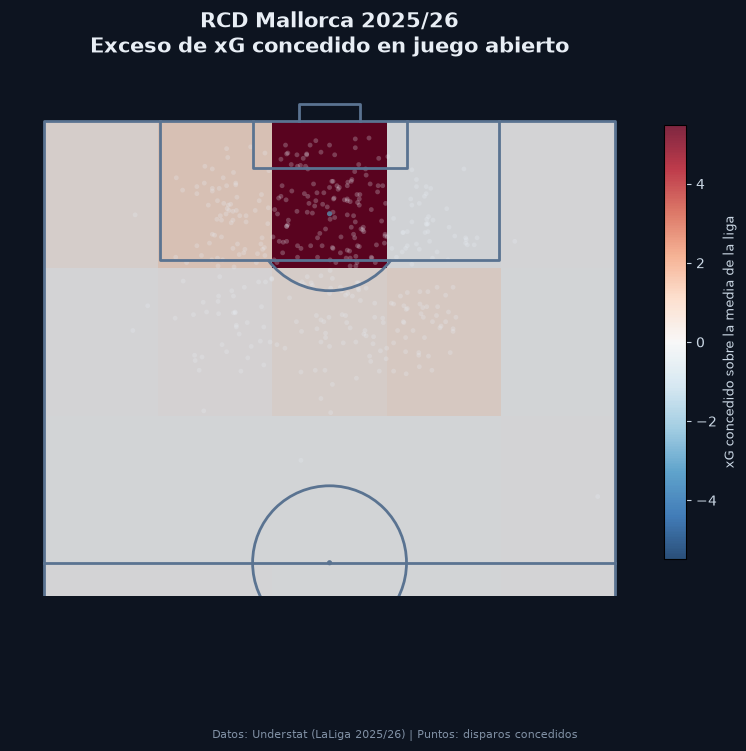

In [9]:
# Convertimos las coordenadas normalizadas a metros reales del campo
abierto["x_m"] = abierto["location_x"] * 105
abierto["y_m"] = abierto["location_y"] * 68

# Separamos los disparos concedidos por el Mallorca
mall = abierto[abierto["rival"] == "Mallorca"]

# Creamos el campo vertical con las lineas por encima del mapa de calor
pitch = VerticalPitch(pitch_type="custom", pitch_length=105, pitch_width=68,
                      half=True, pitch_color="#0d1420", line_color="#5a7391",
                      linewidth=2, line_zorder=3, goal_type="box")

# Creamos la figura
fig, ax = pitch.draw(figsize=(8, 9))
# Aplicamos el color de fondo a toda la figura
fig.set_facecolor("#0d1420")

# Calculamos el xG concedido por el Mallorca en cada casilla del campo
bin_mall = pitch.bin_statistic(mall["x_m"], mall["y_m"], values=mall["xg"],
                               statistic="sum", bins=(6, 5))

# Calculamos el xG concedido por toda la liga en cada casilla
bin_liga = pitch.bin_statistic(abierto["x_m"], abierto["y_m"], values=abierto["xg"],
                               statistic="sum", bins=(6, 5))

# Calculamos el exceso del Mallorca sobre la media por equipo de la liga
bin_mall["statistic"] = bin_mall["statistic"] - (bin_liga["statistic"] / 20)

# Buscamos el valor maximo absoluto para centrar la escala de color en cero
limite = np.nanmax(np.abs(bin_mall["statistic"]))

# Dibujamos el mapa de calor por debajo de las lineas del campo
mapa = pitch.heatmap(bin_mall, ax=ax, cmap="RdBu_r", vmin=-limite, vmax=limite,
                     alpha=0.85, zorder=1)

# Dibujamos los disparos concedidos como puntos para dar contexto
pitch.scatter(mall["x_m"], mall["y_m"], ax=ax, s=12, color="#e8eef5",
              alpha=0.25, edgecolors="none", zorder=2)

# Anadimos la barra de color
barra = fig.colorbar(mapa, ax=ax, shrink=0.5, pad=0.02)
# Ponemos las etiquetas de la barra en color claro
barra.ax.yaxis.set_tick_params(color="#c9d6e3", labelcolor="#c9d6e3")
# Ponemos el titulo de la barra
barra.set_label("xG concedido sobre la media de la liga", color="#c9d6e3", fontsize=9)

# Anadimos el titulo principal separado del borde superior
ax.set_title("RCD Mallorca 2025/26\nExceso de xG concedido en juego abierto",
             color="#e8eef5", fontsize=15, pad=18, fontweight="bold", y=1.02)

# Anadimos la nota con la fuente de los datos
fig.text(0.5, 0.06, "Datos: Understat (LaLiga 2025/26) | Puntos: disparos concedidos",
         color="#7f8fa3", fontsize=8, ha="center")

# Guardamos la imagen
plt.savefig("images/mapa_xg_concedido_mallorca.png", dpi=200,
            facecolor="#0d1420", bbox_inches="tight")
# Mostramos la figura
plt.show()

El mapa confirma el analisis numerico: el exceso de xG concedido por el Mallorca
respecto a la media de la liga se concentra en el pasillo central, desde la frontal
hasta el area pequena, y no en las bandas.

*Fuente: Understat, LaLiga 2025/26.*

## 9. Rendimiento bajo palos

Comprobamos si el desfase de 8,85 goles (encajar menos de lo esperado) se explica
por el rendimiento del portero.

**Limitacion:** Understat proporciona el xG **en el momento del disparo**, no el xG del
tiro ya dirigido a porteria (PSxG), que es la metrica estandar para evaluar porteros.
Al filtrar solo los tiros a puerta nos quedamos con los mejor ejecutados, por lo que el
xG subestima el peligro real y los "goles evitados" salen negativos para todos los
equipos. Lo interpretable es la **posicion relativa**, no el valor absoluto.

In [10]:
# Excluimos los penaltis, donde el portero tiene poco margen de accion
sin_penaltis = disparos_rival[disparos_rival["situation"] != "Penalty"]

# Nos quedamos con los disparos que van a puerta
a_puerta = sin_penaltis[sin_penaltis["result"].isin(["Goal", "Saved Shot", "Shot On Post"])]

# Agrupamos por el equipo que recibio los disparos
porteria = a_puerta.groupby("rival").agg(
    disparos_a_puerta=("xg", "size"),
    xg_a_puerta=("xg", "sum"),
    goles_encajados=("result", lambda r: (r == "Goal").sum()))

# Calculamos los goles evitados respecto a lo esperado
porteria["goles_evitados"] = porteria["xg_a_puerta"] - porteria["goles_encajados"]

# Calculamos el porcentaje de paradas
porteria["pct_paradas"] = (1 - porteria["goles_encajados"] / porteria["disparos_a_puerta"]) * 100

# Calculamos la calidad media de los disparos recibidos
porteria["xg_por_disparo"] = porteria["xg_a_puerta"] / porteria["disparos_a_puerta"]

# Ordenamos de mas a menos goles evitados
porteria = porteria.sort_values("goles_evitados", ascending=False)

# Mostramos la tabla completa
print("RENDIMIENTO BAJO PALOS (sin penaltis)")
print(porteria.round(3))

# Mostramos las medianas como referencia
print("\nMediana de goles evitados:", round(porteria["goles_evitados"].median(), 2))
print("Mediana de porcentaje de paradas:", round(porteria["pct_paradas"].median(), 1), "%")

RENDIMIENTO BAJO PALOS (sin penaltis)
                 disparos_a_puerta  xg_a_puerta  goles_encajados  goles_evitados  pct_paradas  xg_por_disparo
rival                                                                                                        
Barcelona                      128       25.563               32          -6.437       75.000           0.200
Getafe                         158       26.836               35          -8.164       77.848           0.170
Real Madrid                    125       21.567               30          -8.433       76.000           0.173
Atletico Madrid                144       27.275               39         -11.725       72.917           0.189
Rayo Vallecano                 157       24.410               37         -12.590       76.433           0.155
Espanyol                       194       35.927               49         -13.073       74.742           0.185
Celta Vigo                     158       25.794               41         -15.206  

El Mallorca queda **9o de 20 en goles evitados** (-16,19 frente a -17,68 de mediana)
y **15o en porcentaje de paradas** (70,5% frente a 73,3%): rendimiento normal, sin nada
extraordinario.

Donde si destaca es en la **calidad de los disparos recibidos**: 0,198 de xG por tiro a
puerta, de los valores mas altos de la liga y muy por encima de Osasuna (0,137) o
Villarreal (0,151). Le llegaban tiros de mucho peligro, coherente con el analisis del
pasillo central.

**Conclusion:** el desfase de 8,85 goles se explica mejor por **mala ejecucion de los
rivales** que por merito propio. Los datos disponibles no respaldan que el portero fuera
el responsable, aunque la limitacion del xG impide descartarlo del todo.

## 10. Los eventos de partido

A partir de aqui el analisis usa los eventos Opta descargados en el notebook 01: las
acciones de los 380 partidos con su tipo, su jugador y sus coordenadas. Esta celda
comprueba que el fichero esta completo y que tipos de evento recoge.

In [11]:
# Subimos a la carpeta raiz del proyecto para que las rutas relativas funcionen
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import pandas as pd

eventos = pd.read_parquet("data/eventos_laliga_2526.parquet")
print("columnas de eventos:", eventos.columns.tolist())
print("\ntipos de evento mas frecuentes:")
print(eventos["type"].value_counts().head(15))

columnas de eventos: ['game_id', 'period', 'minute', 'second', 'expanded_minute', 'type', 'outcome_type', 'team_id', 'team', 'player_id', 'player', 'x', 'y', 'end_x', 'end_y', 'goal_mouth_y', 'goal_mouth_z', 'blocked_x', 'blocked_y', 'qualifiers', 'is_touch', 'is_shot', 'is_goal', 'card_type', 'event_id', 'related_event_id', 'related_player_id']

tipos de evento mas frecuentes:
type
Pass             362956
BallRecovery      30540
BallTouch         26966
Clearance         19476
Aerial            19468
Foul              19126
TakeOn            14085
Tackle            12574
CornerAwarded      7388
Dispossessed       6354
Interception       6119
Challenge          5844
BlockedPass        5346
SavedShot          4767
Save               4722
Name: count, dtype: int64


## 11. Altura defensiva y acciones del Mallorca

La altura defensiva es la coordenada `x` media de las acciones defensivas de un equipo,
en una escala de 0 a 100 en el sentido de ataque. Cuanto mas baja, mas cerca de su propia
porteria defiende.

Se toman cinco tipos de accion: entradas, intercepciones, despejes, bloqueos de pase y
recuperaciones. Antes se comprueba que las coordenadas estan normalizadas en el sentido
de ataque, mirando donde se concentran los remates.

In [12]:
# Subimos a la carpeta raiz del proyecto para que las rutas relativas funcionen
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import pandas as pd

eventos = pd.read_parquet("data/eventos_laliga_2526.parquet")

ACCIONES_DEF = ["Tackle", "Interception", "Clearance", "BlockedPass", "BallRecovery"]


# ------------------------------------------------------------------
# 1. Comprobamos que las coordenadas van en el sentido de ataque
# ------------------------------------------------------------------
# Si estan normalizadas, los remates se agrupan cerca de x=100
remates = eventos[eventos["is_shot"] == True]
print("COMPROBACION DE COORDENADAS")
print("  x media de los remates:", round(remates["x"].mean(), 1))
print("  x media de las acciones defensivas:",
      round(eventos[eventos["type"].isin(ACCIONES_DEF)]["x"].mean(), 1))


# ------------------------------------------------------------------
# 2. Guardamos las acciones defensivas del Mallorca para el mapa
# ------------------------------------------------------------------
def_mallorca = eventos[(eventos["team"] == "Mallorca")
                       & (eventos["type"].isin(ACCIONES_DEF))][["type", "x", "y"]]

def_mallorca.to_csv("data/acciones_def_mallorca.csv", index=False)
print("\nacciones defensivas del Mallorca:", len(def_mallorca))


# ------------------------------------------------------------------
# 3. Altura defensiva de los veinte equipos, ordenada
# ------------------------------------------------------------------
altura = (eventos[eventos["type"].isin(ACCIONES_DEF)]
          .groupby("team")["x"]
          .mean()
          .sort_values()
          .round(2)
          .reset_index())
altura.columns = ["equipo", "altura_defensiva"]

altura.to_csv("data/altura_defensiva_laliga_2526.csv", index=False)
print("\nALTURA DEFENSIVA POR EQUIPO")
print(altura.to_string(index=False))

COMPROBACION DE COORDENADAS
  x media de los remates: 85.1
  x media de las acciones defensivas: 32.6

acciones defensivas del Mallorca: 3737



ALTURA DEFENSIVA POR EQUIPO
          equipo  altura_defensiva
        Mallorca             29.80
      Villarreal             30.11
          Girona             30.36
     Real Oviedo             30.71
         Osasuna             31.14
      Celta Vigo             31.25
        Valencia             32.00
           Elche             32.00
      Real Betis             32.05
         Levante             32.23
  Rayo Vallecano             32.26
Deportivo Alaves             32.40
          Getafe             32.85
         Sevilla             32.91
        Espanyol             33.24
        Atletico             33.29
   Real Sociedad             33.65
     Real Madrid             35.78
       Barcelona             36.49
   Athletic Club             37.73


**El Mallorca defendia mas abajo que ningun otro equipo de LaLiga**: 29,80, por delante
del Villarreal (30,11) y el Girona (30,36). Este es el valor que usan el trabajo y la
figura 2.

Se guardan tambien sus 3.737 acciones defensivas con coordenadas, que son las que
alimentan el mapa de esa figura.

## 12. Estilo de juego

Caracterizamos como jugaba el equipo a partir de los eventos: altura del bloque,
presion, longitud de pase y volumen de posesion.

In [13]:
# Cargamos el conjunto unificado de eventos
eventos = pd.read_parquet("data/eventos_laliga_2526.parquet")

# Normalizamos el nombre del equipo corrigiendo los que no coinciden
eventos["clave_equipo"] = eventos["team"].apply(normalizar).replace(
    {"atletico": "atletico madrid", "deportivo alaves": "alaves", "real oviedo": "oviedo"})

# Filtramos los pases para analizar el estilo de construccion
pases = eventos[eventos["type"] == "Pass"].copy()

# Marcamos los pases completados
pases["ok"] = pases["outcome_type"] == "Successful"

# Calculamos la longitud de cada pase
pases["largo"] = ((pases["end_x"] - pases["x"])**2 + (pases["end_y"] - pases["y"])**2)**0.5

# Marcamos los pases largos, por encima de 30 unidades
pases["es_largo"] = pases["largo"] >= 30

# Agrupamos las metricas de pase por equipo
estilo = pases.groupby("clave_equipo").agg(
    pases_totales=("ok", "size"),
    pct_acierto=("ok", "mean"),
    largo_medio=("largo", "mean"),
    pct_largos=("es_largo", "mean"))

# Convertimos las proporciones a porcentaje
estilo["pct_acierto"] *= 100
estilo["pct_largos"] *= 100

# Calculamos los pases por partido
estilo["pases_partido"] = estilo["pases_totales"] / 38

# Definimos las acciones defensivas para medir la altura del bloque
acc_def = ["Tackle", "Interception", "Clearance", "BlockedPass", "Challenge"]

# Filtramos las acciones defensivas
defensivas = eventos[eventos["type"].isin(acc_def)]

# Calculamos la altura media a la que cada equipo defiende
estilo["altura_defensiva"] = defensivas.groupby("clave_equipo")["x"].mean()

# Calculamos la altura media a la que cada equipo recupera el balon
recuperaciones = eventos[eventos["type"] == "BallRecovery"]
estilo["altura_recuperacion"] = recuperaciones.groupby("clave_equipo")["x"].mean()

# Guardamos la tabla de estilo
estilo.to_csv("data/estilo_equipos_laliga_2526.csv")

# Mostramos el estilo del Mallorca frente a la mediana de la liga
print("ESTILO DE JUEGO: MALLORCA FRENTE A LA MEDIANA DE LA LIGA")
for col in ["pases_partido", "pct_acierto", "largo_medio", "pct_largos",
            "altura_defensiva", "altura_recuperacion"]:
    # Calculamos el percentil del Mallorca en esa metrica
    pct = (estilo[col] < estilo.loc["mallorca", col]).mean() * 100
    # Mostramos el valor, la mediana y el percentil
    print(f"  {col:22} {round(estilo.loc['mallorca', col], 2):>8}   "
          f"mediana {round(estilo[col].median(), 2):>8}   percentil {round(pct)}")

# Mostramos el ranking de altura defensiva de toda la liga
print("\nALTURA DEFENSIVA (de mas alta a mas baja)")
print(estilo["altura_defensiva"].sort_values(ascending=False).round(2))

ESTILO DE JUEGO: MALLORCA FRENTE A LA MEDIANA DE LA LIGA
  pases_partido            437.92   mediana   453.51   percentil 25
  pct_acierto               79.12   mediana    79.91   percentil 35
  largo_medio               23.34   mediana    22.45   percentil 80
  pct_largos                25.79   mediana    22.68   percentil 75
  altura_defensiva           26.8   mediana    29.94   percentil 0
  altura_recuperacion       36.18   mediana    37.82   percentil 25

ALTURA DEFENSIVA (de mas alta a mas baja)
clave_equipo
athletic club      35.46
barcelona          34.61
real madrid        34.41
real sociedad      31.22
atletico madrid    31.06
sevilla            30.94
espanyol           30.88
getafe             30.86
rayo vallecano     30.02
alaves             29.99
elche              29.88
levante            29.63
real betis         29.56
celta vigo         29.43
valencia           28.94
oviedo             28.51
villarreal         28.05
girona             27.80
osasuna            27.73
mallo

**Estilo resultante: bloque muy bajo, sin presion, juego directo y poca posesion.** Pocos
pases (percentil 25), mas pases largos de lo normal (percentil 75) y menos acierto en el
pase que la media de la liga.

*Cuidado con la altura defensiva de esta tabla.* Aqui se calcula incluyendo `Challenge`
en lugar de `BallRecovery` y da 26,8. La que usa el trabajo y la figura 2 es la del
apartado 11, que son 29,80. Son dos definiciones del mismo concepto y las dos dejan al
Mallorca el ultimo de la liga; se mantienen ambas porque el fichero
`estilo_equipos_laliga_2526.csv` se usa despues en el notebook 03.

Esto explica anomalias que aparecen en el analisis individual, como que Muriqi sea el
delantero que mas despeja de la liga: no son virtudes individuales, son consecuencia del
sistema.

**Matiz importante para el diagnostico:** en un bloque bajo se intercepta menos por
diseno. Lo que sostiene la conclusion del trabajo no es el dato en bruto, sino la
comparacion contra un grupo de control de equipos que cedian territorio similar, que esta
en el notebook 03.

## 13. Intercepciones y exposicion defensiva

Comprobacion a nivel de equipo: si interceptar mas se tradujera en conceder menos, tendria
que aparecer una correlacion negativa entre ambas cosas.

El cruce entre las dos fuentes falla en dos equipos porque escriben el nombre de forma
distinta (`atletico` frente a `atletico madrid`, `deportivo alaves` frente a `alaves`).
La segunda celda lo corrige y cierra los 20.

In [14]:
import pandas as pd
from unidecode import unidecode

largo = pd.read_csv("data/equipos_largo_laliga_2526.csv")


# Unificamos la forma de escribir los nombres de los equipos
def normalizar(nombre):
    n = unidecode(str(nombre)).lower().replace(".", "").replace("-", " ")
    return " ".join(n.split())


# Intercepciones por partido de cada equipo
inter = (eventos[eventos["type"] == "Interception"]
         .groupby("team")
         .size()
         .rename("intercepciones"))

partidos = eventos.groupby("team")["game_id"].nunique().rename("partidos")

defensivo = pd.concat([inter, partidos], axis=1)
defensivo["inter_partido"] = defensivo["intercepciones"] / defensivo["partidos"]
defensivo["clave"] = defensivo.index.map(normalizar)

# Exposicion defensiva: lo que concede cada equipo por partido
exposicion = (largo.groupby("equipo")
              .agg(xga_partido=("xga", "mean"),
                   goles_encajados_partido=("goles_encajados", "mean")))
exposicion["clave"] = exposicion.index.map(normalizar)

# Cruzamos las dos fuentes
tabla = defensivo.merge(exposicion, on="clave", how="inner")
print("equipos cruzados:", len(tabla), "de 20")

if len(tabla) < 20:
    print("\nsin cruzar en eventos:",
          sorted(set(defensivo["clave"]) - set(exposicion["clave"])))
    print("sin cruzar en largo:",
          sorted(set(exposicion["clave"]) - set(defensivo["clave"])))

print("\nCORRELACIONES CON LAS INTERCEPCIONES POR PARTIDO")
print("  xGA por partido:",
      round(tabla["inter_partido"].corr(tabla["xga_partido"]), 3))
print("  goles encajados por partido:",
      round(tabla["inter_partido"].corr(tabla["goles_encajados_partido"]), 3))

print("\nDETALLE POR EQUIPO")
print(tabla[["clave", "inter_partido", "xga_partido", "goles_encajados_partido"]]
      .round(2)
      .sort_values("xga_partido", ascending=False)
      .to_string(index=False))

equipos cruzados: 18 de 20

sin cruzar en eventos: ['atletico', 'deportivo alaves']
sin cruzar en largo: ['alaves', 'atletico madrid']

CORRELACIONES CON LAS INTERCEPCIONES POR PARTIDO
  xGA por partido: -0.053
  goles encajados por partido: 0.256

DETALLE POR EQUIPO
         clave  inter_partido  xga_partido  goles_encajados_partido
         elche           8.16         1.81                     1.50
   real oviedo           7.92         1.78                     1.58
       levante           8.74         1.75                     1.61
        girona           7.68         1.73                     1.45
      mallorca           7.21         1.73                     1.50
      espanyol           8.37         1.65                     1.45
       sevilla           8.58         1.61                     1.58
 real sociedad           7.87         1.59                     1.61
    celta vigo           7.21         1.48                     1.26
rayo vallecano           8.29         1.48          

In [15]:
# Corregimos los nombres que cada fuente escribe de forma distinta
CORRECCIONES = {"atletico": "atletico madrid", "deportivo alaves": "alaves"}

defensivo["clave"] = defensivo["clave"].replace(CORRECCIONES)
exposicion["clave"] = exposicion["clave"].replace(CORRECCIONES)

tabla = defensivo.merge(exposicion, on="clave", how="inner")
print("equipos cruzados:", len(tabla), "de 20")
print("xGA por partido:",
      round(tabla["inter_partido"].corr(tabla["xga_partido"]), 3))
print("goles encajados:",
      round(tabla["inter_partido"].corr(tabla["goles_encajados_partido"]), 3))

equipos cruzados: 20 de 20
xGA por partido: -0.03
goles encajados: 0.253


**No hay relacion.** La correlacion entre intercepciones por partido y xGA por partido es
de **-0,03**, practicamente cero. A nivel de equipo el volumen de intercepciones no
explica lo que se concede, porque depende sobre todo de cuanto balon tenga el rival.

Es el mismo resultado que vuelve a salir en el notebook 06 con una regresion sobre los
20 equipos. Por eso el analisis de la anticipacion se hace por jugador y contra un grupo
de control, no comparando equipos entre si.

## 14. Pases clave y origen de las ocasiones

Opta marca con el calificador `KeyPass` el pase que genera un remate, y con `Cross` los
centros. Cruzando los dos se puede medir que parte de las ocasiones de cada equipo nace
de un centro.

La primera celda comprueba que los calificadores estan ahi; la segunda filtra solo los
que son pases, porque `KeyPass` aparece tambien en otros tipos de evento.

In [16]:
# Buscamos si los calificadores permiten identificar los centros
texto = eventos.loc[eventos["type"] == "Pass", "qualifiers"].astype(str)

print("pases totales:", len(texto))
print("con 'Cross':", int(texto.str.contains("Cross").sum()))
print("con 'Longball':", int(texto.str.contains("Longball").sum()))
print("con 'KeyPass':",
      int(eventos["qualifiers"].astype(str).str.contains("KeyPass").sum()))

pases totales: 362956
con 'Cross': 13395


con 'Longball': 48045


con 'KeyPass': 7070


In [17]:
import pandas as pd

eventos = pd.read_parquet("data/eventos_laliga_2526.parquet")
texto = eventos["qualifiers"].astype(str)

# Nos quedamos con los pases que el proveedor marca como pase clave
es_clave = texto.str.contains("KeyPass")
print("eventos con KeyPass por tipo:")
print(eventos.loc[es_clave, "type"].value_counts().to_string())

clave = eventos[es_clave & (eventos["type"] == "Pass")].copy()
clave["es_centro"] = texto[clave.index].str.contains("Cross")

print("\npases clave totales:", len(clave))
print("de ellos centros:", int(clave["es_centro"].sum()))

eventos con KeyPass por tipo:
type
Pass             6648
BallTouch         261
MissedShots        67
Tackle             28
SavedShot          22
BlockedPass        17
Interception       16
Clearance           7
CornerAwarded       2
Foul                1
Dispossessed        1

pases clave totales: 6648
de ellos centros: 1901


In [18]:
# Porcentaje de ocasiones que nacen de un centro, equipo a equipo
resumen = (clave.groupby("team")["es_centro"]
           .agg(pases_clave="size", centros="sum"))
resumen["pct_centros"] = (resumen["centros"]
                          / resumen["pases_clave"] * 100).round(1)

print(resumen.sort_values("pct_centros", ascending=False).to_string())
print("\nmediana de la liga:", resumen["pct_centros"].median())

                  pases_clave  centros  pct_centros
team                                               
Osasuna                   301      133         44.2
Getafe                    215       89         41.4
Mallorca                  285      116         40.7
Espanyol                  324      127         39.2
Deportivo Alaves          303      105         34.7
Real Oviedo               249       86         34.5
Valencia                  296       98         33.1
Levante                   301       97         32.2
Athletic Club             353      112         31.7
Atletico                  378      117         31.0
Elche                     308       91         29.5
Sevilla                   306       87         28.4
Rayo Vallecano            372      102         27.4
Real Sociedad             342       89         26.0
Girona                    297       71         23.9
Real Betis                381       85         22.3
Villarreal                324       62         19.1
Barcelona   

**El 40,7 % de las ocasiones del Mallorca nacian de un centro**, frente al 30,3 % de
mediana de la liga. Solo Osasuna (44,2 %) y Getafe (41,4 %) dependian mas del centro.

Y con 285 pases clave en toda la temporada es el tercer registro mas bajo de LaLiga: solo
Getafe (215) y Oviedo (249) crearon menos. Creaba poco y casi siempre de la misma forma.

La ultima celda guarda el origen y el destino de esos pases para la figura 3.

In [19]:
# Guardamos el origen de los pases clave para el notebook de figuras
columnas = ["team", "x", "y", "end_x", "end_y", "es_centro"]
clave[columnas].to_csv("data/pases_clave_laliga_2526.csv", index=False)
print("guardado:", len(clave), "pases clave")

guardado: 6648 pases clave


---
## Conclusiones del diagnostico

1. El Mallorca descendio **mereciendolo**: 18o en puntos esperados, con 2,21 puntos
   mas de los que merecio.
2. El ataque **no era eficaz ni ineficaz**: convirtio exactamente lo que generaba,
   pero generaba muy poco (17o en xG, percentil 10 en llegadas al area rival).
3. La carencia principal es **defensiva y en juego abierto** (91% del exceso).
4. Se concentra en el **pasillo central**, en zona de remate (82% del exceso).
5. **No es un problema de balon parado** ni de juego aereo.
6. **El portero no explica el desfase**: encajaron menos de lo esperado por fallos
   de los rivales, no por meritos propios. Sin esa fortuna habrian encajado cerca de 66 goles.
7. El equipo jugaba con el **bloque mas bajo de la liga**, un plan que exige centrales
   dominantes y que no funciono.

El perfil de refuerzo apunta al **eje defensivo**. La identificacion por jugador se
aborda en el notebook 03.